In [71]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay,classification_report

In [72]:
# read dataset
df=pd.read_csv("Student_Performance_Dataset.csv")

In [73]:
df

,Student_ID,Age,Gender,Class,Study_Hours_Per_Day,Attendance_Percentage,Parental_Education,Internet_Access,Extracurricular_Activities,Math_Score,Science_Score,English_Score,Previous_Year_Score,Final_Percentage,Performance_Level,Pass_Fail
0,S0001,15,Male,12,1.0,65,Postgraduate,No,No,40,39,72,81,50.33,Average,Pass
1,S0002,19,Female,9,1.6,58,Graduate,No,Yes,80,44,35,47,53.00,Average,Pass
2,S0003,14,Female,12,3.6,64,High School,Yes,Yes,83,73,59,58,71.67,Good,Pass
3,S0004,18,Female,9,5.5,68,Postgraduate,Yes,No,68,48,77,54,64.33,Average,Pass
4,S0005,14,Male,10,5.0,80,High School,Yes,No,41,46,36,68,41.00,Poor,Fail
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,S4996,17,Male,11,4.0,50,Graduate,No,No,64,60,70,93,64.67,Average,Pass
4996,S4997,19,Male,10,5.6,90,High School,Yes,No,44,59,43,63,48.67,Poor,Fail
4997,S4998,16,Female,9,2.3,61,Graduate,No,No,95,41,82,62,72.67,Good,Pass
4998,S4999,15,Male,11,2.9,82,Graduate,No,Yes,66,45,61,75,57.33,Average,Pass


In [74]:
# Investigate shape of dataset
df.shape

(5000, 16)

In [75]:
# Investigate null values
df.isnull().sum()

Student_ID                    0
Age                           0
Gender                        0
Class                         0
Study_Hours_Per_Day           0
Attendance_Percentage         0
Parental_Education            0
Internet_Access               0
Extracurricular_Activities    0
Math_Score                    0
Science_Score                 0
English_Score                 0
Previous_Year_Score           0
Final_Percentage              0
Performance_Level             0
Pass_Fail                     0
dtype: int64

In [76]:
# Investigate duplicated values
df.duplicated().sum()

np.int64(0)

In [77]:
# invstigate columns info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  5000 non-null   str    
 1   Age                         5000 non-null   int64  
 2   Gender                      5000 non-null   str    
 3   Class                       5000 non-null   int64  
 4   Study_Hours_Per_Day         5000 non-null   float64
 5   Attendance_Percentage       5000 non-null   int64  
 6   Parental_Education          5000 non-null   str    
 7   Internet_Access             5000 non-null   str    
 8   Extracurricular_Activities  5000 non-null   str    
 9   Math_Score                  5000 non-null   int64  
 10  Science_Score               5000 non-null   int64  
 11  English_Score               5000 non-null   int64  
 12  Previous_Year_Score         5000 non-null   int64  
 13  Final_Percentage            5000 non-null   

In [78]:
# Create a copy of origina dataset 
data=df.copy()

In [79]:
# Drop Student idcolumn
data=data.drop(columns="Student_ID")

In [80]:
# Investigate data inconsistence
for col in data.select_dtypes(include="str").columns:
    print(data[col].value_counts())
    print()

Gender
Female    2553
Male      2447
Name: count, dtype: int64

Parental_Education
Postgraduate    1679
Graduate        1661
High School     1660
Name: count, dtype: int64

Internet_Access
No     2622
Yes    2378
Name: count, dtype: int64

Extracurricular_Activities
Yes    2519
No     2481
Name: count, dtype: int64

Performance_Level
Good         2191
Average      1951
Excellent     593
Poor          265
Name: count, dtype: int64

Pass_Fail
Pass    4735
Fail     265
Name: count, dtype: int64



In [81]:
# Inestigate impossible valuews in the dataset
for col in data.select_dtypes(include="number").columns:
    if col=="Age":
        a=data[col]<10
        if a.sum()>0:
            print(data.loc[a,col],col)
    else:
        a=data[col]<0
        if a.sum()>0:
            print(data.loc[a,col],col)

In [82]:
# separate features and target
feature=data.drop(columns="Pass_Fail")
target=data["Pass_Fail"].str.replace({
    "Pass":"1",
    "Fail":"0"
})
target=target.astype("int")

In [83]:
# split dataset
x_train,x_test,y_train,y_test=train_test_split(
    feature,
    target,
    test_size=20,
    stratify=target,
    random_state=43
)

In [84]:
# Separate numerical olumns
numerical_cols=data.select_dtypes(include="number").columns

In [85]:
# Separate categorical columns
categorical_cols=(data.select_dtypes(include="str").columns).drop("Pass_Fail")

In [86]:
# Initiate categorical pipeline
preprocessor=Pipeline([
    ("encoder",OneHotEncoder(handle_unknown='ignore'))
]
)

In [87]:
# Initaite main pipeline
tree_pipeline=Pipeline(steps=[
("preprecossing",preprocessor),
("model",DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=5,
    min_samples_split=5,
    criterion="gini",
    random_state=34
))
]
)

In [88]:
# Train
tree_pipeline.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprecossing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sort

In [89]:
# Evaluate
y_train_predicted=tree_pipeline.predict(x_train)

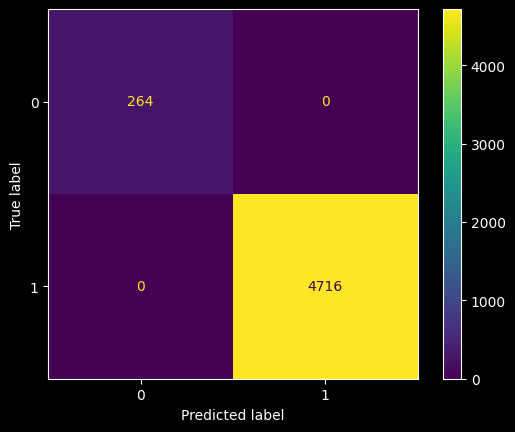

In [90]:
Conf_train=ConfusionMatrixDisplay.from_predictions(y_train,y_train_predicted)

In [97]:
print(classification_report(y_train,y_train_predicted))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       264
           1       1.00      1.00      1.00      4716

    accuracy                           1.00      4980
   macro avg       1.00      1.00      1.00      4980
weighted avg       1.00      1.00      1.00      4980



In [94]:
# Test
y_test_predicted=tree_pipeline.predict(x_test)

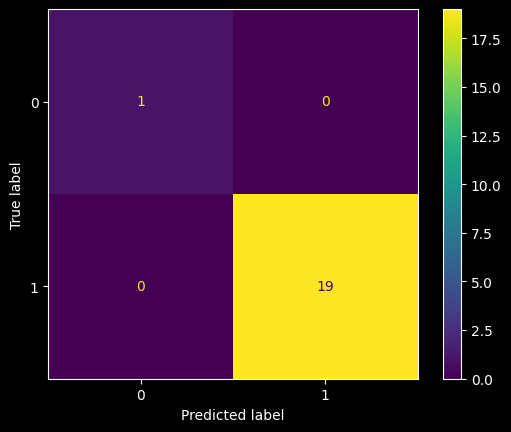

In [95]:
conf_test=ConfusionMatrixDisplay.from_predictions(y_test,y_test_predicted)

In [96]:
# Classifiucation report
print(classification_report(y_test,y_test_predicted))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00        19

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20

